# OpenSTEF reload and Beam backtest

One load area, so this stays small enough to run. The stored model was trained on archive weather from 2018. That weather is reanalysis, so it is a more generous view of the future than a forecast that would have been published at the time.

The Beam section does not reuse that model. It retrains on a schedule and may use a weather value only after `run_initialized_at` plus `forecast_runs.publication_delay_hours` (6 hours by default). Metered load is hidden until `load_availability_delay_hours` after the hour begins (1 hour by default). ECMWF IFS HRES single runs start on 2024-03-14. The default Beam window starts on 2026-01-01. Each fit looks back `training_context_days` (90), so the download has to start on 2025-10-03. A file that only covers January 2026 leaves that window almost empty of weather, the fit is skipped, and the metrics come back empty.

Train and download first:

```bash
python -c "from pjm_forecasting.flows.training import train_load_areas; train_load_areas(areas='AECO')"
python src/update_historical_weather_runs.py --start 2025-10-03 --end 2026-01-15 --areas AECO
```

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from pjm_forecasting import load_area_model, predict_quantiles, run_area_backtest
from pjm_forecasting.ingest.openmeteo import build_versioned_load
from pjm_forecasting.preprocessing import prepare_openstef_frame
from pjm_forecasting.settings import load_settings
from pjm_forecasting.splits import split_chronological
from pjm_forecasting.training import score_forecast

AREA = "AECO"
settings = load_settings()
frame_path = settings.processed_dir / "load_area_hourly.parquet"
predictor_path = settings.versioned_predictor_dir() / f"{AREA}.parquet"
print(settings.tracking_uri)
print("publication delay", settings.publication_delay)
print("load delay", settings.load_delay)
print("forecast-run archive starts", settings.archive_start)

/Users/mehuljain/Documents/Projects/forecast-energy/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sqlite:////Users/mehuljain/Documents/Projects/forecast-energy/mlflow.db
publication delay 6:00:00
load delay 1:00:00
forecast-run archive starts 2024-03-14 00:00:00+00:00


## Holdout from the stored final model

This reload reads the MLflow run named `final`. The forecast below still uses archive weather on the 2026 holdout, so it is not the leakage-safe score. It is the model that a normal prediction would use.

In [2]:
joined = pd.read_parquet(frame_path)
prepared = prepare_openstef_frame(joined, AREA)
split = split_chronological(prepared, settings.train_end, settings.validation_end)
history = pd.concat([split.train, split.validation, split.test]).sort_index()
origin = split.test.index.min()
workflow = load_area_model(AREA, settings=settings)
forecast = predict_quantiles(AREA, history, origin, workflow=workflow, settings=settings)
holdout_metrics = score_forecast(split.test["load"], forecast)
holdout_metrics

{'n': 48.0,
 'mae': 44.09544818115234,
 'rmse': 56.725666955768084,
 'pinball_p10': 12.290647226969403,
 'pinball_p50': 22.04772409057617,
 'pinball_p90': 11.896426762898768,
 'coverage_p10_p90': 0.5833333333333334}

## Beam backtest

Change `BEAM_END` for a longer window. Beam fits again inside the window, using only load and forecast runs that were already published.

In [3]:
BEAM_END = pd.Timestamp("2026-01-08", tz="US/Eastern")
predictors = pd.read_parquet(predictor_path)
versioned_load = build_versioned_load(joined, AREA, settings.load_delay)
backtest = run_area_backtest(
    AREA,
    versioned_load,
    predictors,
    settings=settings,
    start=settings.backtest_start,
    end=BEAM_END,
    show_progress=True,
)
print(backtest["assumptions"])
print(backtest["start"], "->", backtest["end"])
backtest["metrics"]

100%|██████████| 26/26 [00:03<00:00,  8.30it/s]

Archive weather from 2018 trains the stored model. Beam does not use that model. It retrains on metered load and ECMWF IFS HRES single runs. A run initialized at run_initialized_at is treated as published publication_delay later. Metered load for an hour is treated as known load_availability_delay after the hour begins. The default backtest starts in 2026, after the 2024-03-14 start of the IFS HRES single-run archive.
2026-01-01T00:00:00-05:00 -> 2026-01-08T00:00:00-05:00


{'n': 1200.0,
 'mae': 60.37691039591471,
 'rmse': 85.74768055447225,
 'pinball_p10': 31.018080785278325,
 'pinball_p50': 30.188455197957357,
 'pinball_p90': 14.94886922265625,
 'coverage_p10_p90': 0.22166666666666668}

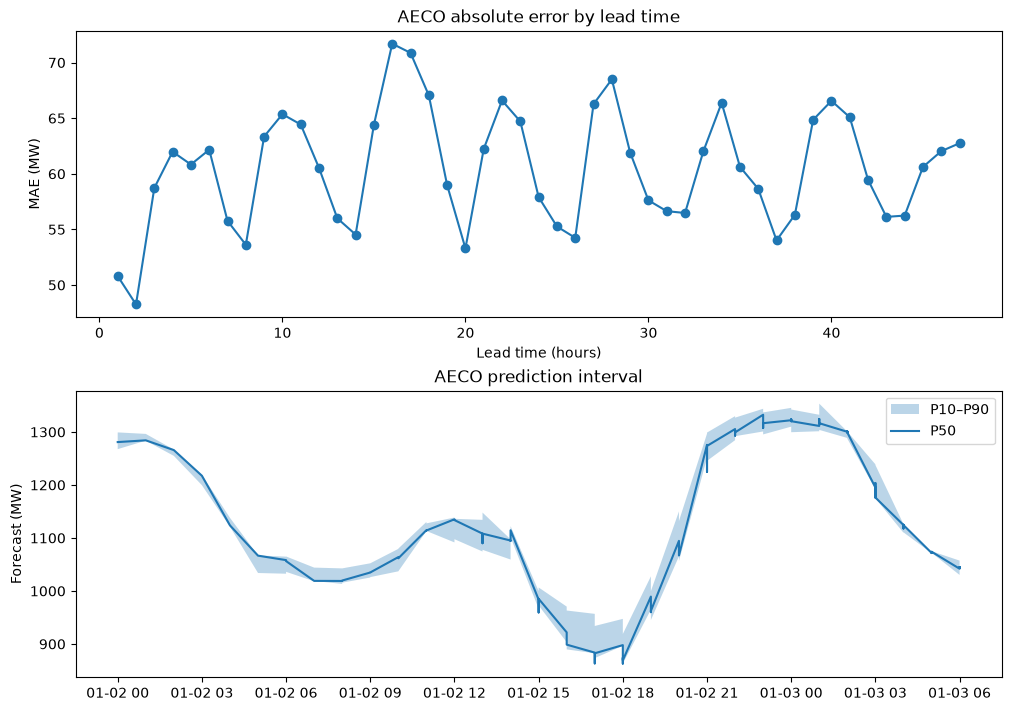

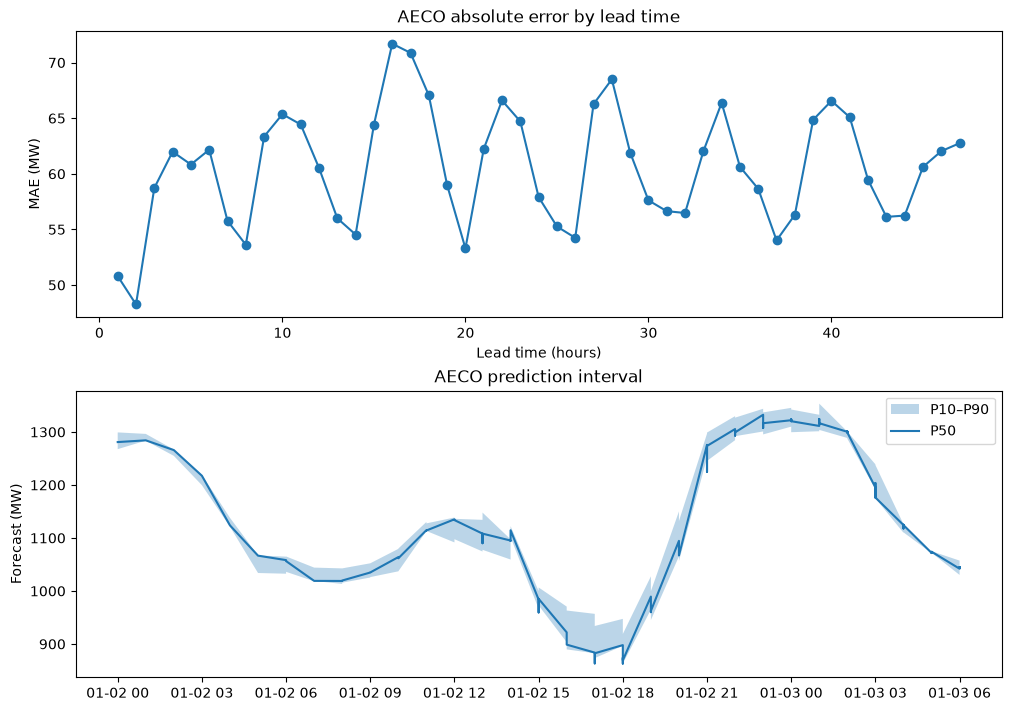

In [4]:
lead = backtest["lead_time_errors"]
lead = lead.loc[(lead["lead_hours"] >= 1) & (lead["lead_hours"] <= settings.prediction_length)]
fig, axes = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True)
axes[0].plot(lead["lead_hours"], lead["mae"], marker="o")
axes[0].set_xlabel("Lead time (hours)")
axes[0].set_ylabel("MAE (MW)")
axes[0].set_title(f"{AREA} absolute error by lead time")

view = backtest["predictions"].sort_index().iloc[: settings.prediction_length * 2]
axes[1].fill_between(view.index, view["quantile_P10"], view["quantile_P90"], alpha=0.3, label="P10–P90")
axes[1].plot(view.index, view["quantile_P50"], label="P50")
axes[1].set_ylabel("Forecast (MW)")
axes[1].set_title(f"{AREA} prediction interval")
axes[1].legend()
fig

24h-ahead hourly bias span 75.7 MW, mean MAE 59.8 MW, n=191


,bias_mw,mae_mw,n
hour,,,
0,-17.3,32.0,8
1,-14.2,27.2,8
2,-16.4,24.5,8
3,-17.4,24.9,8
4,-15.5,20.2,8
5,5.2,31.9,8
6,21.2,25.8,8
7,28.7,33.9,8
8,4.5,36.2,8


,bias_mw,mae_mw,n
weekday,,,
Monday,8.9,33.8,24
Tuesday,3.9,39.0,24
Wednesday,-99.3,100.7,24
Thursday,-66.3,70.6,28
Friday,38.8,55.4,43
Saturday,25.8,43.5,24
Sunday,-76.6,78.1,24


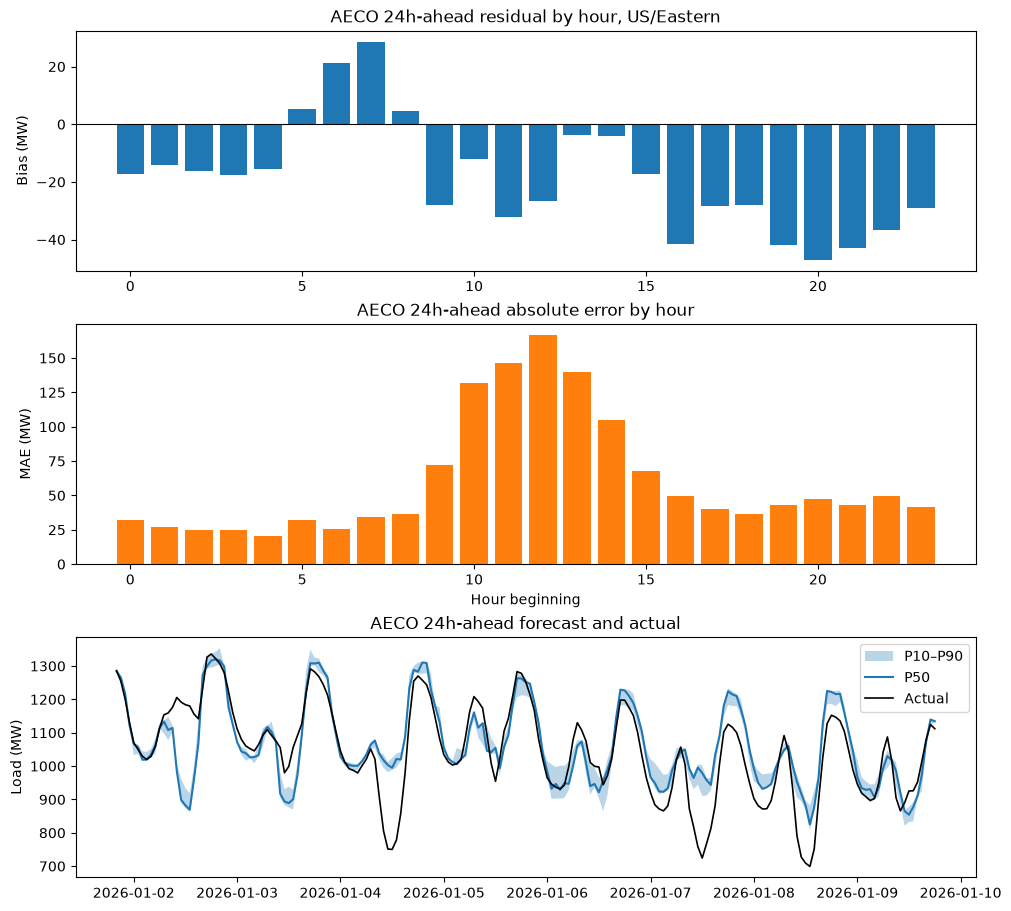

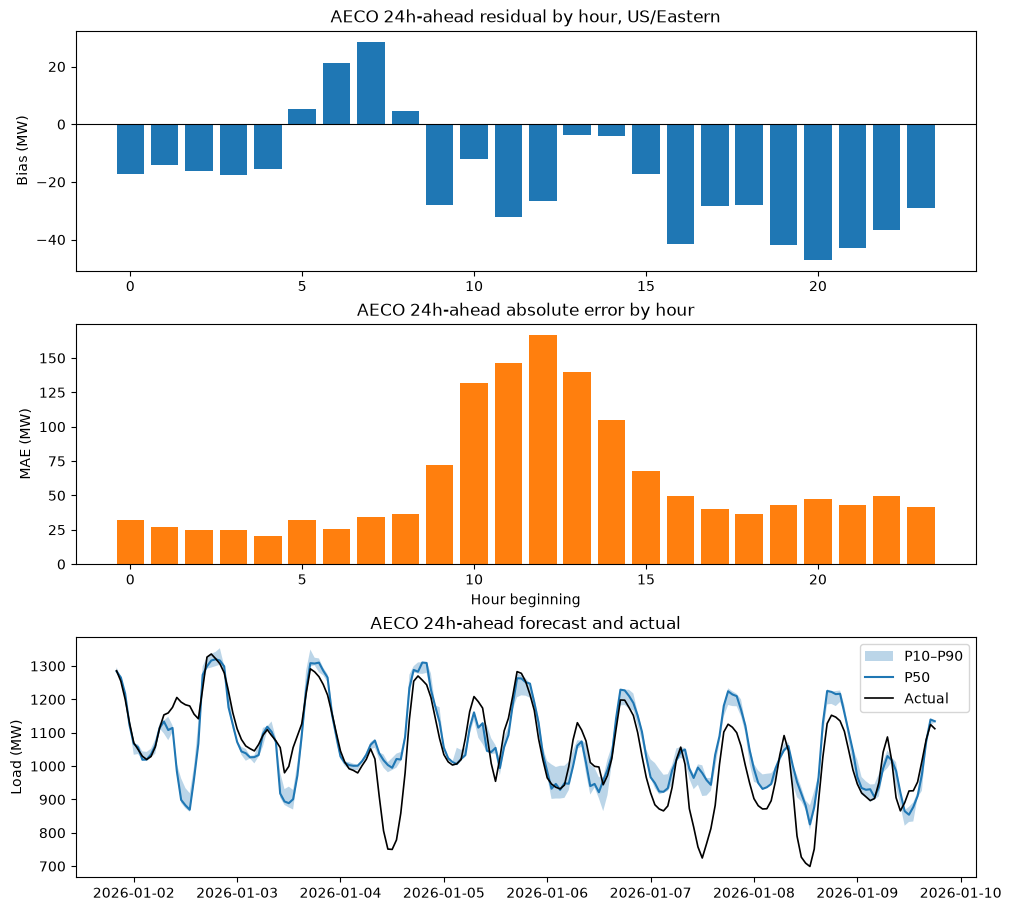

In [5]:
LEAD_HOURS = 24

forecasts = backtest["predictions"].reset_index()
stamps = pd.to_datetime(forecasts["timestamp"], utc=True)
issued = pd.to_datetime(forecasts["available_at"], utc=True)
forecasts["lead_hours"] = (stamps - issued).dt.total_seconds() / 3600.0
forecasts = forecasts.loc[forecasts["lead_hours"].between(1, settings.prediction_length)].copy()
forecasts["lead_gap"] = (forecasts["lead_hours"] - LEAD_HOURS).abs()
day_ahead = (
    forecasts.sort_values(["lead_gap", "available_at"], kind="mergesort")
    .groupby("timestamp", as_index=False)
    .head(1)
    .sort_values("timestamp")
)

day_ahead["local"] = pd.to_datetime(day_ahead["timestamp"], utc=True).dt.tz_convert("US/Eastern")
actual = prepared["load"].copy()
actual.index = actual.index.tz_convert("US/Eastern")
day_ahead["actual"] = day_ahead["local"].map(actual)
day_ahead = day_ahead.dropna(subset=["actual", "quantile_P50"]).copy()
day_ahead["residual"] = day_ahead["actual"] - day_ahead["quantile_P50"]
day_ahead["hour"] = day_ahead["local"].dt.hour
day_ahead["weekday"] = day_ahead["local"].dt.day_name()

summary = {"bias_mw": ("residual", "mean"), "mae_mw": ("residual", lambda s: s.abs().mean()), "n": ("residual", "size")}
by_hour = (
    day_ahead.groupby("hour")
    .agg(**summary)
    .reindex(range(24))
)
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_weekday = (
    day_ahead.groupby("weekday")
    .agg(**summary)
    .reindex(weekday_order)
    .dropna(how="all")
)
bias_span = by_hour["bias_mw"].max() - by_hour["bias_mw"].min()
print(
    f"24h-ahead hourly bias span {bias_span:.1f} MW, "
    f"mean MAE {by_hour['mae_mw'].mean():.1f} MW, n={len(day_ahead)}"
)
display(by_hour.round(1))
display(by_weekday.round(1))

fig, axes = plt.subplots(3, 1, figsize=(10, 9), constrained_layout=True)
axes[0].bar(by_hour.index, by_hour["bias_mw"], color="C0")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Bias (MW)")
axes[0].set_title(f"{AREA} 24h-ahead residual by hour, US/Eastern")
axes[1].bar(by_hour.index, by_hour["mae_mw"], color="C1")
axes[1].set_xlabel("Hour beginning")
axes[1].set_ylabel("MAE (MW)")
axes[1].set_title(f"{AREA} 24h-ahead absolute error by hour")

axes[2].fill_between(
    day_ahead["local"], day_ahead["quantile_P10"], day_ahead["quantile_P90"], alpha=0.3, label="P10–P90"
)
axes[2].plot(day_ahead["local"], day_ahead["quantile_P50"], label="P50")
axes[2].plot(day_ahead["local"], day_ahead["actual"], label="Actual", color="black", linewidth=1.2)
axes[2].set_ylabel("Load (MW)")
axes[2].set_title(f"{AREA} 24h-ahead forecast and actual")
axes[2].legend()
fig